# AI for Clinical Diagnostics — CNN & RNN

Two real clinical problems, solved with the two classic deep-learning families:

| Part | Clinical problem | Data | Model |
|------|------------------|------|-------|
| **A** | **Pneumonia screening from pediatric chest X-rays** | Kermany et al., *Cell* 2018 — 5,856 expert-graded X-rays | **CNN** (EfficientNet-B0 transfer learning + Grad-CAM) |
| **B** | **Arrhythmia detection from ECG heartbeats** | MIT-BIH Arrhythmia Database (PhysioNet) — 48 half-hour recordings, ~110k cardiologist-labelled beats | **RNN** (CNN-BiLSTM over the beat waveform + RR-interval rhythm features) |

Both are evaluated the way a clinical study would be: on a held-out test set, with sensitivity / specificity / PPV
rather than plain accuracy, and (for the ECG) on **patients the model has never seen**.

**Run on Google Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all* (≈ 20–30 min total).
All datasets (~1.3 GB) are pulled automatically from the Hugging Face Hub in the first cells.

> ⚠️ Educational project — not a medical device.

## 0. Setup & pull the datasets

In [1]:
import os, io, json, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from PIL import Image
from scipy.ndimage import median_filter
from scipy.signal import butter, filtfilt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
import tensorflow as tf
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (enable it: Runtime → Change runtime type)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATA_DIR = "data"
HF = "https://huggingface.co/datasets"

def download(url, rel_path):
    """Download url to DATA_DIR/rel_path once; return the local path."""
    path = os.path.join(DATA_DIR, rel_path)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print(f"downloading {rel_path} ...", flush=True)
        urllib.request.urlretrieve(url, path + ".part")
        os.replace(path + ".part", path)
    return path

# Chest X-ray Images (Pneumonia) — Kermany et al. 2018, CC BY 4.0
XRAY_REPO = f"{HF}/hf-vision/chest-xray-pneumonia/resolve/main/data/"
XRAY_FILES = {
    "train": [f"train-{i:05d}-of-00007.parquet" for i in range(7)],
    "validation": ["validation-00000-of-00001.parquet"],
    "test": ["test-00000-of-00001.parquet"],
}
# MIT-BIH Arrhythmia Database (PhysioNet), mirrored on the HF Hub
ECG_URL = f"{HF}/epr-labs/mit-bih-arrhythmia-database/resolve/main/data/train-00000-of-00001.parquet"

for split, files in XRAY_FILES.items():
    for f in files:
        download(XRAY_REPO + f, f"chest_xray/{f}")
ECG_PATH = download(ECG_URL, "mitbih/mitbih.parquet")
print("All datasets ready in", os.path.abspath(DATA_DIR))

downloading chest_xray/train-00000-of-00007.parquet ...
downloading chest_xray/train-00001-of-00007.parquet ...
downloading chest_xray/train-00002-of-00007.parquet ...
downloading chest_xray/train-00003-of-00007.parquet ...
downloading chest_xray/train-00004-of-00007.parquet ...
downloading chest_xray/train-00005-of-00007.parquet ...
downloading chest_xray/train-00006-of-00007.parquet ...
downloading chest_xray/validation-00000-of-00001.parquet ...
downloading chest_xray/test-00000-of-00001.parquet ...
downloading mitbih/mitbih.parquet ...
All datasets ready in /content/data


---
# Part A — Pneumonia Screening from Chest X-rays (CNN)

## A1. Problem statement
Pneumonia is the single largest infectious cause of death in children under five worldwide (WHO). Chest X-rays are
the standard diagnostic tool, but in many regions there are not enough radiologists to read them quickly.

**Goal:** a model that reads a pediatric chest X-ray and flags likely pneumonia, so that flagged cases are
prioritised for a radiologist (*triage*).

**What "good" means clinically:**
* **Sensitivity (recall on PNEUMONIA)** must be high — a missed pneumonia is the costly error.
* **Specificity** should stay acceptable, otherwise the radiologist is flooded with false alarms.
* We report **ROC-AUC** (threshold-free) and pick an **operating threshold on the validation set** that targets ≥ 95 % sensitivity.

**Data:** 5,856 anterior-posterior X-rays of children aged 1–5 (Guangzhou Women and Children's Medical Center),
graded by two expert physicians. Labels: `NORMAL` / `PNEUMONIA` (bacterial + viral).

## A2. Load & resize the images
The original JPEGs are ~2000 px. We decode them in grayscale and resize to 224 × 224 (the EfficientNet input size).
The decoded arrays are cached to `data/*.npz` so re-runs are instant.

In [3]:
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = 224

def load_xrays(split, size):
    cache = os.path.join(DATA_DIR, f"chest_xray_{split}_{size}.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        return d["x"], d["y"]
    xs, ys = [], []
    for f in XRAY_FILES[split]:
        table = pq.read_table(download(XRAY_REPO + f, f"chest_xray/{f}"))
        for img, label in zip(table.column("image").to_pylist(), table.column("label").to_pylist()):
            im = Image.open(io.BytesIO(img["bytes"]))
            im.draft("L", (size * 2, size * 2))           # fast JPEG down-scaled decode
            im = im.convert("L").resize((size, size), Image.BILINEAR)
            xs.append(np.asarray(im, np.uint8))
            ys.append(label)
    x, y = np.stack(xs)[..., None], np.array(ys, np.int32)
    np.savez_compressed(cache, x=x, y=y)
    return x, y

t0 = time.time()
x_train_full, y_train_full = load_xrays("train", IMG_SIZE)
x_val_orig, y_val_orig = load_xrays("validation", IMG_SIZE)
x_test, y_test = load_xrays("test", IMG_SIZE)
print(f"decoded in {time.time() - t0:.0f}s")

for name, y in [("train", y_train_full), ("official val", y_val_orig), ("test", y_test)]:
    n, p = np.bincount(y, minlength=2)
    print(f"{name:13s} {len(y):5d} images | NORMAL {n:5d} | PNEUMONIA {p:5d} ({p / len(y):.0%})")

decoded in 53s
train          5216 images | NORMAL  1341 | PNEUMONIA  3875 (74%)
official val     16 images | NORMAL     8 | PNEUMONIA     8 (50%)
test            624 images | NORMAL   234 | PNEUMONIA   390 (62%)


## A3. Train / validation split
The official validation split has only **16 images** — far too few to tune anything. We merge it into the training data
and carve out a **stratified 15 % validation set**. The official **test set (624 images) is never touched** until the final evaluation.

Note the **class imbalance**: ~74 % of training images are PNEUMONIA. We counter it with **class weights**.

In [4]:
x_all = np.concatenate([x_train_full, x_val_orig])
y_all = np.concatenate([y_train_full, y_val_orig])
x_tr, x_val, y_tr, y_val = train_test_split(x_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)

counts = np.bincount(y_tr)
class_weight = {i: len(y_tr) / (2 * c) for i, c in enumerate(counts)}
print("train:", x_tr.shape, "val:", x_val.shape, "test:", x_test.shape)
print("class weights:", {CLASS_NAMES[k]: round(v, 2) for k, v in class_weight.items()})

train: (4447, 224, 224, 1) val: (785, 224, 224, 1) test: (624, 224, 224, 1)
class weights: {'NORMAL': np.float64(1.94), 'PNEUMONIA': np.float64(0.67)}


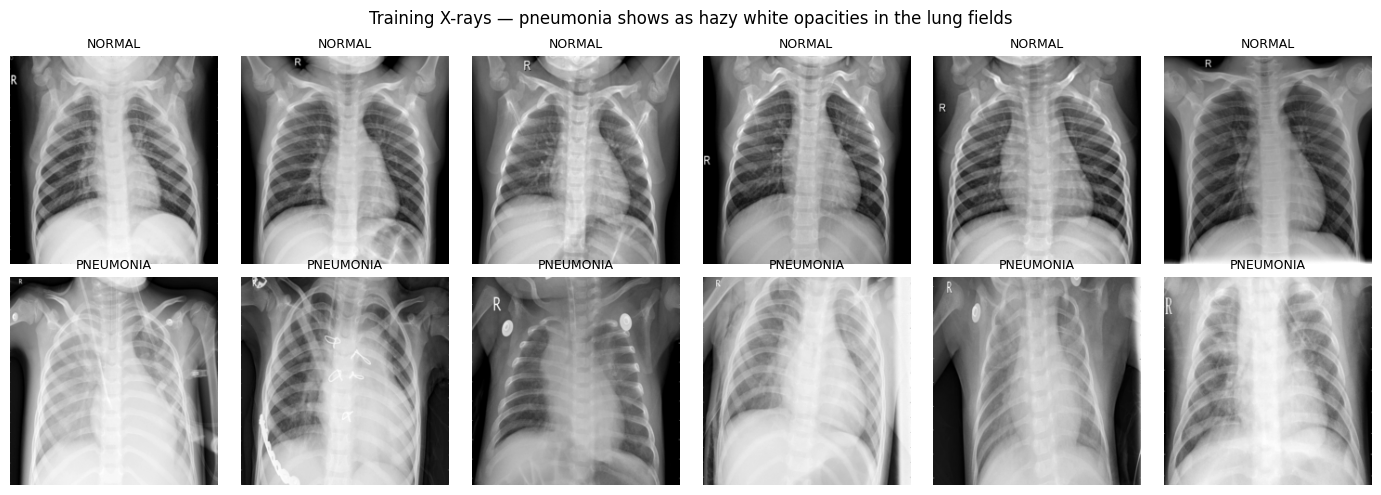

In [5]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
rng = np.random.default_rng(SEED)
for row, cls in enumerate([0, 1]):
    for ax, i in zip(axes[row], rng.choice(np.where(y_tr == cls)[0], 6, replace=False)):
        ax.imshow(x_tr[i, :, :, 0], cmap="gray")
        ax.set_title(CLASS_NAMES[cls], fontsize=9)
        ax.axis("off")
plt.suptitle("Training X-rays — pneumonia shows as hazy white opacities in the lung fields")
plt.tight_layout()
plt.show()

## A4. Input pipeline & augmentation
Augmentation mimics real acquisition variability: small rotations, shifts, zoom and contrast changes.
We deliberately **do not flip horizontally** — chest anatomy is asymmetric (the heart sits on the left).

In [6]:
BATCH = 32

def make_ds(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y.astype("float32")))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_ds(x_tr, y_tr, training=True)
val_ds = make_ds(x_val, y_val)
test_ds = make_ds(x_test, y_test)

augment = keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.15),
], name="augment")

## A5. Model — EfficientNet-B0 transfer learning
With ~5k images, training a deep CNN from scratch overfits. Instead we reuse **EfficientNet-B0 pretrained on ImageNet**
as a feature extractor and train a small classification head on top. The gray image is repeated to 3 channels;
EfficientNet does its own pixel normalisation internally (it expects 0–255 inputs).

In [7]:
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                       input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

gap = layers.GlobalAveragePooling2D(name="gap")
head_dropout = layers.Dropout(0.3, name="head_dropout")
head = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")

inputs = keras.Input((IMG_SIZE, IMG_SIZE, 1))
x = augment(inputs)
x = layers.Concatenate(name="gray_to_rgb")([x, x, x])
x = base(x, training=False)          # keep BatchNorm in inference mode, also when fine-tuning
outputs = head(head_dropout(gap(x)))
cnn = keras.Model(inputs, outputs, name="pneumonia_cnn")

METRICS = [keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="sensitivity"),
           keras.metrics.Precision(name="precision"), keras.metrics.BinaryAccuracy(name="accuracy")]
cnn.summary(show_trainable=True)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "pneumonia_cnn"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1     │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 1)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ augment           │ (None, 224,     │         0 │ input_layer_1… │   -   │
│ (Sequential)      │ 224, 1)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ gray_to_rgb       │ (None, 224,     │         0 │ augment[0][0], │   -   │
│ (Concatenate)     │ 224, 3)         │           │ augment[0][0], │       │
│                   │                 │           │ augment[0][0]  │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ efficientnetb0    │ (None, 7, 7,    │ 4,049,571 │ gray_to_rgb[0… │   N   │
│ (Functional)      │ 1280)           │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ gap               │ (None, 1280)    │         0 │ efficientnetb… │   -   │
│ (GlobalAveragePo… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ head_dropout      │ (None, 1280)    │         0 │ gap[0][0]      │   -   │
│ (Dropout)         │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ pneumonia_prob    │ (None, 1)       │     1,281 │ head_dropout[… │   Y   │
│ (Dense)           │                 │           │                │       │
└───────────────────┴─────────────────┴───────────┴────────────────┴───────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### A6. Stage 1 — train the head (backbone frozen)

In [8]:
HEAD_EPOCHS = 5
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=METRICS)
hist1 = cnn.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, class_weight=class_weight, verbose=2)

Epoch 1/5
139/139 - 30s - 213ms/step - accuracy: 0.8095 - auc: 0.9096 - loss: 0.4139 - precision: 0.9388 - sensitivity: 0.7952 - val_accuracy: 0.8879 - val_auc: 0.9726 - val_loss: 0.2657 - val_precision: 0.9825 - val_sensitivity: 0.8645
Epoch 2/5
139/139 - 11s - 82ms/step - accuracy: 0.8970 - auc: 0.9659 - loss: 0.2577 - precision: 0.9696 - sensitivity: 0.8891 - val_accuracy: 0.9197 - val_auc: 0.9786 - val_loss: 0.1967 - val_precision: 0.9710 - val_sensitivity: 0.9194
Epoch 3/5
139/139 - 11s - 82ms/step - accuracy: 0.9071 - auc: 0.9742 - loss: 0.2204 - precision: 0.9731 - sensitivity: 0.8997 - val_accuracy: 0.9274 - val_auc: 0.9803 - val_loss: 0.1771 - val_precision: 0.9696 - val_sensitivity: 0.9314
Epoch 4/5
139/139 - 11s - 83ms/step - accuracy: 0.9186 - auc: 0.9800 - loss: 0.1957 - precision: 0.9757 - sensitivity: 0.9130 - val_accuracy: 0.9299 - val_auc: 0.9817 - val_loss: 0.1719 - val_precision: 0.9731 - val_sensitivity: 0.9314
Epoch 5/5
139/139 - 12s - 84ms/step - accuracy: 0.9231 

### A7. Stage 2 — fine-tune the top of the backbone
We unfreeze the last ~60 layers (BatchNorm layers stay frozen) and continue with a 30× lower learning rate,
keeping the epoch with the best validation AUC.

In [9]:
FINE_TUNE_EPOCHS = 15
base.trainable = True
for layer in base.layers[:-60]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

cnn.compile(optimizer=keras.optimizers.Adam(3e-5), loss="binary_crossentropy", metrics=METRICS)
hist2 = cnn.fit(
    train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS, class_weight=class_weight, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.3, patience=2)],
)

Epoch 1/15
139/139 - 28s - 203ms/step - accuracy: 0.9364 - auc: 0.9843 - loss: 0.1563 - precision: 0.9821 - sensitivity: 0.9312 - val_accuracy: 0.9363 - val_auc: 0.9877 - val_loss: 0.1458 - val_precision: 0.9872 - val_sensitivity: 0.9262 - learning_rate: 3.0000e-05
Epoch 2/15
139/139 - 14s - 102ms/step - accuracy: 0.9476 - auc: 0.9889 - loss: 0.1306 - precision: 0.9833 - sensitivity: 0.9455 - val_accuracy: 0.9554 - val_auc: 0.9901 - val_loss: 0.1153 - val_precision: 0.9858 - val_sensitivity: 0.9537 - learning_rate: 3.0000e-05
Epoch 3/15
139/139 - 15s - 105ms/step - accuracy: 0.9570 - auc: 0.9929 - loss: 0.1050 - precision: 0.9868 - sensitivity: 0.9548 - val_accuracy: 0.9656 - val_auc: 0.9912 - val_loss: 0.0951 - val_precision: 0.9810 - val_sensitivity: 0.9726 - learning_rate: 3.0000e-05
Epoch 4/15
139/139 - 14s - 102ms/step - accuracy: 0.9606 - auc: 0.9943 - loss: 0.0922 - precision: 0.9894 - sensitivity: 0.9573 - val_accuracy: 0.9682 - val_auc: 0.9919 - val_loss: 0.0871 - val_precisio

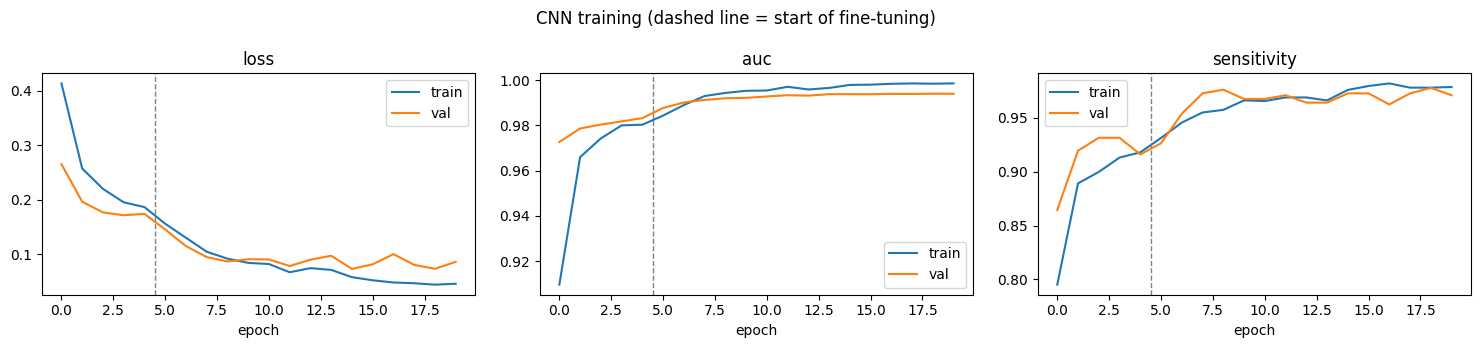

In [10]:
def concat_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

h = concat_hist(hist1, hist2)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, key in zip(ax, ["loss", "auc", "sensitivity"]):
    a.plot(h[key], label="train"); a.plot(h["val_" + key], label="val")
    a.axvline(len(hist1.history["loss"]) - 0.5, color="gray", ls="--", lw=1)
    a.set_title(key); a.set_xlabel("epoch"); a.legend()
plt.suptitle("CNN training (dashed line = start of fine-tuning)")
plt.tight_layout()
plt.show()

## A8. Choose the operating threshold (on validation, not test)
A default 0.5 threshold is arbitrary. For triage we pick the threshold that gives the **highest specificity while keeping
sensitivity ≥ 95 %** on the validation set, then freeze it and apply it to the test set.

In [11]:
TARGET_SENSITIVITY = 0.95
p_val = cnn.predict(val_ds, verbose=0).ravel()
fpr, tpr, thr = roc_curve(y_val, p_val)
ok = tpr >= TARGET_SENSITIVITY
THRESHOLD = float(thr[ok][np.argmin(fpr[ok])])
print(f"Validation AUC {roc_auc_score(y_val, p_val):.4f}")
print(f"Chosen threshold {THRESHOLD:.3f} → val sensitivity {tpr[ok][np.argmin(fpr[ok])]:.3f}, "
      f"val specificity {1 - fpr[ok].min():.3f}")

Validation AUC 0.9957
Chosen threshold 0.815 → val sensitivity 0.964, val specificity 0.985


## A9. Final evaluation on the held-out test set

In [12]:
p_test = cnn.predict(test_ds, verbose=0).ravel()

def binary_report(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": round(thr, 3), "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "PPV": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1), "accuracy": (tp + tn) / len(y_true),
            "missed pneumonia (FN)": int(fn), "false alarms (FP)": int(fp)}

test_auc = roc_auc_score(y_test, p_test)
print(f"TEST ROC-AUC: {test_auc:.4f}\n")
display(pd.DataFrame([binary_report(y_test, p_test, 0.5), binary_report(y_test, p_test, THRESHOLD)],
                     index=["default 0.5", "triage threshold"]).round(3))

pred_test = (p_test >= THRESHOLD).astype(int)
print(classification_report(y_test, pred_test, target_names=CLASS_NAMES, digits=3))

TEST ROC-AUC: 0.9712



,threshold,sensitivity,specificity,PPV,NPV,accuracy,missed pneumonia (FN),false alarms (FP)
default 0.5,0.500,0.997,0.526,0.778,0.992,0.821,1,111
triage threshold,0.815,0.992,0.632,0.818,0.980,0.857,3,86


              precision    recall  f1-score   support

      NORMAL      0.980     0.632     0.769       234
   PNEUMONIA      0.818     0.992     0.897       390

    accuracy                          0.857       624
   macro avg      0.899     0.812     0.833       624
weighted avg      0.879     0.857     0.849       624



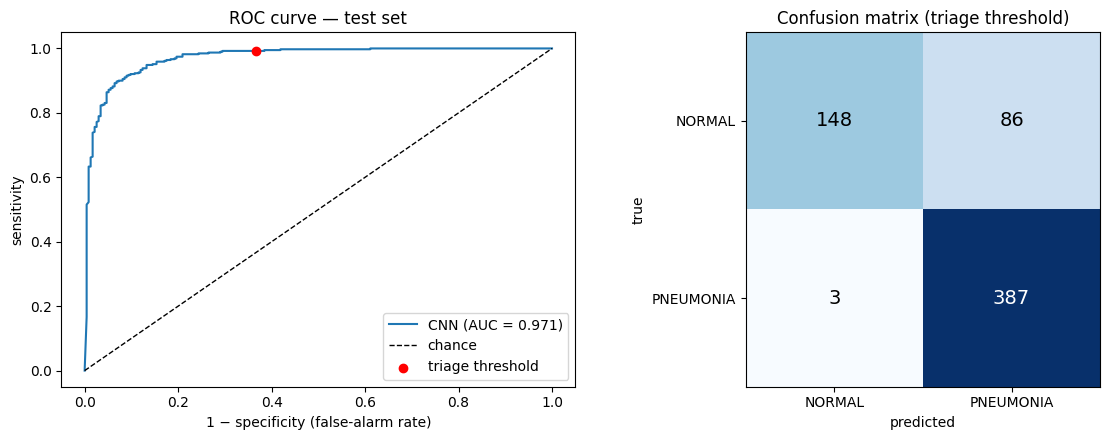

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
fpr_t, tpr_t, _ = roc_curve(y_test, p_test)
ax[0].plot(fpr_t, tpr_t, label=f"CNN (AUC = {test_auc:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="chance")
r = binary_report(y_test, p_test, THRESHOLD)
ax[0].scatter(1 - r["specificity"], r["sensitivity"], c="red", zorder=3, label="triage threshold")
ax[0].set_xlabel("1 − specificity (false-alarm rate)"); ax[0].set_ylabel("sensitivity")
ax[0].set_title("ROC curve — test set"); ax[0].legend()

cm = confusion_matrix(y_test, pred_test)
ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1], CLASS_NAMES); ax[1].set_yticks([0, 1], CLASS_NAMES)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true"); ax[1].set_title("Confusion matrix (triage threshold)")
plt.tight_layout()
plt.show()

## A10. Explainability — Grad-CAM
A clinician will not trust a black box. **Grad-CAM** highlights which regions drove the prediction:
it weights the last convolutional feature maps by the gradient of the pneumonia probability.
Sensible heatmaps sit over the lung fields; heatmaps on text markers or borders would reveal *shortcut learning*.

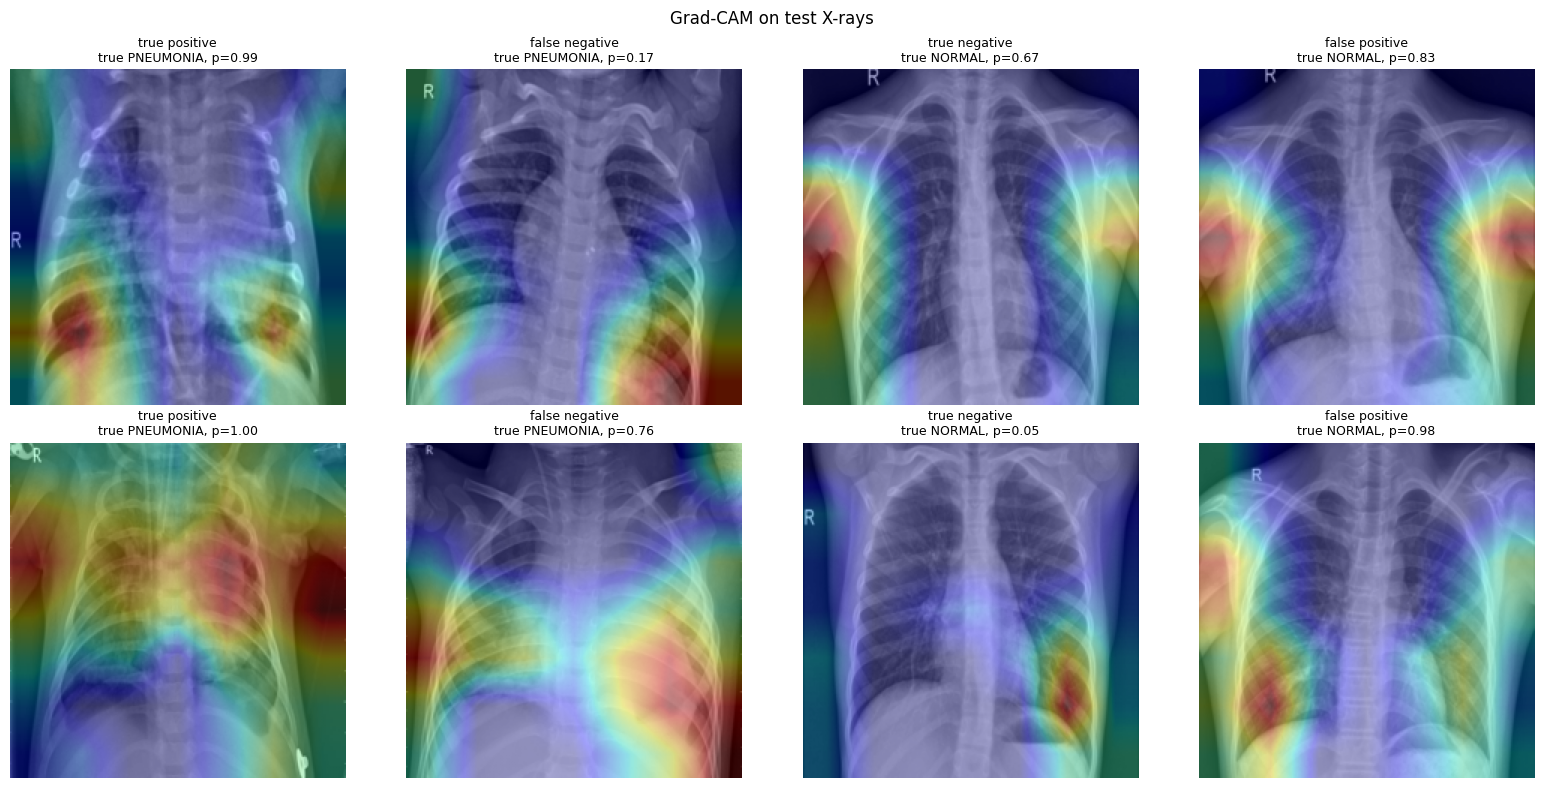

In [14]:
def grad_cam(img_uint8):
    x = tf.cast(img_uint8[None], tf.float32)
    x = tf.concat([x, x, x], axis=-1)
    with tf.GradientTape() as tape:
        feats = base(x, training=False)            # (1, 7, 7, 1280)
        tape.watch(feats)
        prob = head(gap(feats))
    grads = tape.gradient(prob, feats)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(feats[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()
    return cam, float(prob[0, 0])

groups = {"true positive": (y_test == 1) & (pred_test == 1), "false negative": (y_test == 1) & (pred_test == 0),
          "true negative": (y_test == 0) & (pred_test == 0), "false positive": (y_test == 0) & (pred_test == 1)}
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, (name, mask) in enumerate(groups.items()):
    idx = np.where(mask)[0]
    for row in range(2):
        ax = axes[row, col]
        ax.axis("off")
        if row >= len(idx):
            continue
        i = idx[row]
        cam, p = grad_cam(x_test[i])
        ax.imshow(x_test[i, :, :, 0], cmap="gray")
        ax.imshow(cam, cmap="jet", alpha=0.35)
        ax.set_title(f"{name}\ntrue {CLASS_NAMES[y_test[i]]}, p={p:.2f}", fontsize=9)
plt.suptitle("Grad-CAM on test X-rays")
plt.tight_layout()
plt.show()

In [15]:
os.makedirs("models", exist_ok=True)
cnn.save("models/pneumonia_cnn.keras")
with open("models/pneumonia_cnn_threshold.json", "w") as f:
    json.dump({"threshold": THRESHOLD, "target_sensitivity": TARGET_SENSITIVITY}, f)
print("Saved models/pneumonia_cnn.keras (+ threshold)")

Saved models/pneumonia_cnn.keras (+ threshold)


---
# Part B — Arrhythmia Detection from ECG Heartbeats (RNN)

## B1. Problem statement
Arrhythmias (irregular heartbeats) can signal heart disease and precede stroke or sudden cardiac death. They are often
intermittent, so patients wear a **Holter monitor** for 24–48 h — that's ~100,000 beats per day, far too many to
review by hand.

**Goal:** classify every heartbeat into the **ANSI/AAMI EC57** standard classes:

| Class | Meaning | Beat types |
|---|---|---|
| **N** | Normal / bundle-branch-block beats | N, L, R, e, j |
| **S** | Supraventricular ectopic beat (SVEB) | A, a, J, S |
| **V** | Ventricular ectopic beat (VEB) | V, E |
| **F** | Fusion of ventricular and normal beat | F |

(Class Q — paced/unclassifiable — is excluded, and so are the 4 paced records, as in the AAMI standard.)

**The hard part — generalising to new patients.** ECG morphology is very patient-specific. If beats from the same
person end up in both train and test, models score ~99 % — but that's memorisation. We use the **inter-patient
split of de Chazal et al. (2004)**: 22 records (DS1) for training, 22 *different patients* (DS2) for testing.

**Metrics:** per-class **sensitivity** and **positive predictive value (PPV)**, and **macro-F1**.
Accuracy is misleading here — ~90 % of beats are normal.

## B2. Load the recordings
Each record is 30 min of 2-lead ECG at 360 Hz, with a beat-by-beat annotation from cardiologists.
We use the **MLII** lead (record 114 has it on the second channel).

In [16]:
FS = 360
ecg_table = pq.read_table(ECG_PATH)
signals = ecg_table.column("signals").combine_chunks()
records = {}
for i, (hdr, samples, symbols) in enumerate(zip(ecg_table.column("header").to_pylist(),
                                                ecg_table.column("annotation_sample").to_pylist(),
                                                ecg_table.column("annotation_symbol").to_pylist())):
    hdr = json.loads(hdr)
    sig = signals[i].values.flatten().to_numpy(zero_copy_only=False).reshape(-1, hdr["n_sig"])
    records[hdr["record_name"]] = {"signal": sig[:, hdr["sig_name"].index("MLII")] if "MLII" in hdr["sig_name"] else None,
                                   "samples": np.array(samples), "symbols": np.array(symbols)}
print(len(records), "records:", " ".join(records))

DS1 = ["101", "106", "108", "109", "112", "114", "115", "116", "118", "119", "122",
       "124", "201", "203", "205", "207", "208", "209", "215", "220", "223", "230"]
DS2 = ["100", "103", "105", "111", "113", "117", "121", "123", "200", "202", "210",
       "212", "213", "214", "219", "221", "222", "228", "231", "232", "233", "234"]
assert not set(DS1) & set(DS2)

48 records: 100 101 102 103 104 105 106 107 108 109 111 112 113 114 115 116 117 118 119 121 122 123 124 200 201 202 203 205 207 208 209 210 212 213 214 215 217 219 220 221 222 223 228 230 231 232 233 234


## B3. Signal pre-processing & beat segmentation
1. **Baseline-wander removal** — two median filters (200 ms then 600 ms) estimate the slow drift, which we subtract.
2. **35 Hz low-pass** (Butterworth, zero-phase) removes muscle noise and power-line interference.
3. **Per-record z-score.**
4. Around each annotated R-peak, cut a window from **250 ms before to 450 ms after** (the P-QRS-T complex), downsampled to 180 Hz → **126 time steps**.
5. **Rhythm features** from RR intervals (time between beats): previous RR, next RR, local average RR (last 10 beats), and their ratios
   to the patient's average. Premature S beats look almost normal in shape but arrive *early* — this is how cardiologists spot them.

In [17]:
AAMI = {**dict.fromkeys("NLRej", "N"), **dict.fromkeys("AaJS", "S"), **dict.fromkeys("VE", "V"),
        "F": "F", **dict.fromkeys("/fQ", "Q")}
CLASSES = ["N", "S", "V", "F"]
BEFORE, AFTER, DOWN = int(0.25 * FS), int(0.45 * FS), 2
b_lp, a_lp = butter(3, 35 / (FS / 2), btype="low")

def clean(sig):
    baseline = median_filter(median_filter(sig, int(0.2 * FS) | 1), int(0.6 * FS) | 1)
    x = filtfilt(b_lp, a_lp, sig - baseline)
    return ((x - x.mean()) / x.std()).astype(np.float32)

def extract_beats(name):
    rec = records[name]
    sig = clean(rec["signal"])
    is_beat = np.isin(rec["symbols"], list(AAMI))
    samples, symbols = rec["samples"][is_beat], rec["symbols"][is_beat]
    rr = np.diff(samples) / FS
    mean_rr = rr.mean()
    X, R, Y, POS = [], [], [], []
    for i in range(1, len(samples) - 1):
        cls, s = AAMI[symbols[i]], samples[i]
        if cls == "Q" or s - BEFORE < 0 or s + AFTER > len(sig):
            continue
        pre, post, local = rr[i - 1], rr[i], rr[max(0, i - 10):i].mean()
        X.append(sig[s - BEFORE:s + AFTER:DOWN])
        R.append([pre, post, local, pre / mean_rr, post / mean_rr, pre / local, post / pre])
        Y.append(CLASSES.index(cls))
        POS.append(s)
    return np.array(X), np.array(R, np.float32), np.array(Y, np.int32), np.array(POS)

def build(names):
    parts = [extract_beats(n) for n in names]
    rec_ids = np.concatenate([[n] * len(p[2]) for n, p in zip(names, parts)])
    return [np.concatenate(z) for z in zip(*parts)] + [rec_ids]

t0 = time.time()
Xb1, R1, Y1, P1, REC1 = build(DS1)
Xb2, R2, Y2, P2, REC2 = build(DS2)
print(f"segmented in {time.time() - t0:.0f}s | beat window: {Xb1.shape[1]} steps | RR features: {R1.shape[1]}")

display(pd.DataFrame({"DS1 (train)": np.bincount(Y1, minlength=4), "DS2 (test)": np.bincount(Y2, minlength=4)},
                     index=CLASSES).assign(**{"DS1 %": lambda d: (100 * d["DS1 (train)"] / d["DS1 (train)"].sum()).round(2)}))

segmented in 4s | beat window: 126 steps | RR features: 7


,DS1 (train),DS2 (test),DS1 %
N,45824,44218,89.91
S,943,1836,1.85
V,3788,3219,7.43
F,414,388,0.81


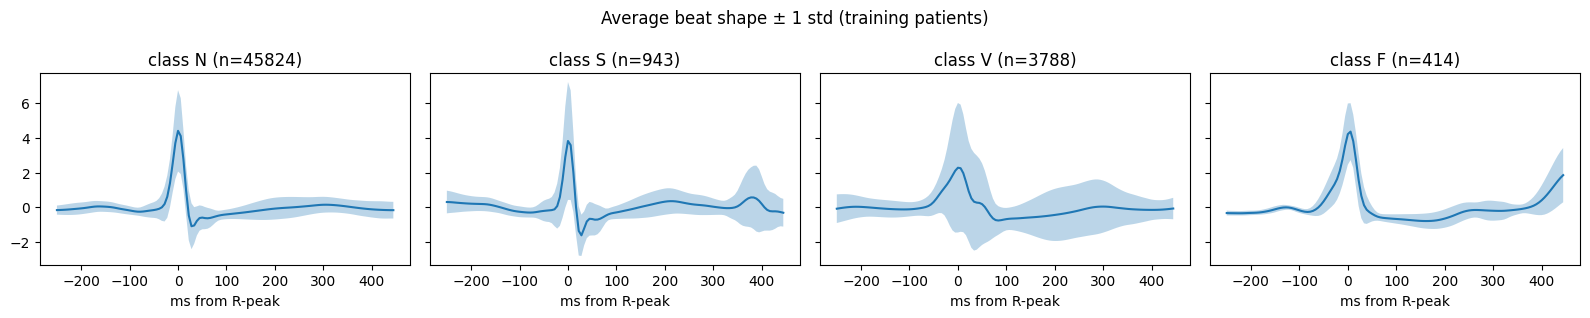

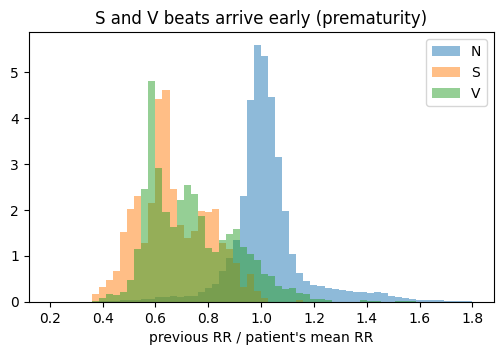

In [18]:
t_ms = (np.arange(Xb1.shape[1]) * DOWN - BEFORE) / FS * 1000
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, c in zip(axes, range(4)):
    beats = Xb1[Y1 == c]
    m, s = beats.mean(0), beats.std(0)
    ax.plot(t_ms, m); ax.fill_between(t_ms, m - s, m + s, alpha=0.3)
    ax.set_title(f"class {CLASSES[c]} (n={len(beats)})"); ax.set_xlabel("ms from R-peak")
plt.suptitle("Average beat shape ± 1 std (training patients)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
for c in range(3):
    ax.hist(R1[Y1 == c, 3], bins=60, range=(0.2, 1.8), alpha=0.5, density=True, label=CLASSES[c])
ax.set_xlabel("previous RR / patient's mean RR"); ax.set_title("S and V beats arrive early (prematurity)"); ax.legend()
plt.show()

## B4. Train / validation / test
* **Test = DS2** — 22 unseen patients.
* Validation = a stratified 10 % of DS1 beats (used only for early stopping).
* RR features are standardised with training statistics.
* Strong class imbalance (N ≫ V > S > F) → **square-root-balanced class weights** (full inverse-frequency weights would over-boost the tiny F class).

In [19]:
idx_tr, idx_val = train_test_split(np.arange(len(Y1)), test_size=0.1, stratify=Y1, random_state=SEED)
rr_mean, rr_std = R1[idx_tr].mean(0), R1[idx_tr].std(0)
norm_rr = lambda r: (r - rr_mean) / rr_std

def inputs_for(Xb, R, idx=slice(None)):
    return {"beat": Xb[idx][..., None], "rr": norm_rr(R[idx])}

X_tr, X_val, X_te = inputs_for(Xb1, R1, idx_tr), inputs_for(Xb1, R1, idx_val), inputs_for(Xb2, R2)
y_tr_e, y_val_e, y_te_e = Y1[idx_tr], Y1[idx_val], Y2

cnt = np.bincount(y_tr_e, minlength=4)
ecg_class_weight = {c: float(np.sqrt(len(y_tr_e) / (4 * cnt[c]))) for c in range(4)}
print("class weights:", {CLASSES[c]: round(w, 2) for c, w in ecg_class_weight.items()})

class weights: {'N': 0.53, 'S': 3.68, 'V': 1.83, 'F': 5.54}


## B5. Model — CNN-BiLSTM with rhythm features
* **Waveform branch:** a 1-D convolution acts as a learned filter bank and halves the sequence length, then two stacked
  **bidirectional LSTMs** read the beat as a time series (P-wave → QRS → T-wave) in both directions.
* **Rhythm branch:** a small dense layer over the RR-interval features.
* The two are concatenated and classified into N / S / V / F.

In [20]:
T = Xb1.shape[1]
beat_in = keras.Input((T, 1), name="beat")
rr_in = keras.Input((R1.shape[1],), name="rr")

x = layers.Conv1D(32, 7, padding="same", activation="relu")(beat_in)
x = layers.MaxPooling1D(2)(x)
x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
x = layers.Bidirectional(layers.LSTM(32))(x)
r = layers.Dense(32, activation="relu")(rr_in)
z = layers.Concatenate()([x, r])
z = layers.Dropout(0.3)(z)
z = layers.Dense(64, activation="relu")(z)
ecg_out = layers.Dense(len(CLASSES), activation="softmax")(z)

rnn = keras.Model([beat_in, rr_in], ecg_out, name="ecg_cnn_bilstm")
rnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
rnn.summary()

Model: "ecg_cnn_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ beat (InputLayer)   │ (None, 126, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 126, 32)   │        256 │ beat[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 63, 32)    │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 63, 128)   │     49,664 │ max_pooling1d[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rr (InputLayer)     │ (None, 7)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 64)        │     41,216 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        256 │ rr[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96)        │          0 │ bidirectional_1[… │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 96)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      6,208 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 4)         │        260 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 97,860 (382.27 KB)

 Trainable params: 97,860 (382.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
180/180 - 8s - 45ms/step - accuracy: 0.9409 - loss: 0.3404 - val_accuracy: 0.9684 - val_loss: 0.1928 - learning_rate: 0.0010
Epoch 2/30
180/180 - 3s - 19ms/step - accuracy: 0.9650 - loss: 0.1659 - val_accuracy: 0.9692 - val_loss: 0.1406 - learning_rate: 0.0010
Epoch 3/30
180/180 - 3s - 19ms/step - accuracy: 0.9720 - loss: 0.1259 - val_accuracy: 0.9761 - val_loss: 0.1137 - learning_rate: 0.0010
Epoch 4/30
180/180 - 3s - 19ms/step - accuracy: 0.9760 - loss: 0.1051 - val_accuracy: 0.9814 - val_loss: 0.0695 - learning_rate: 0.0010
Epoch 5/30
180/180 - 3s - 19ms/step - accuracy: 0.9795 - loss: 0.0870 - val_accuracy: 0.9802 - val_loss: 0.0661 - learning_rate: 0.0010
Epoch 6/30
180/180 - 3s - 19ms/step - accuracy: 0.9806 - loss: 0.0837 - val_accuracy: 0.9780 - val_loss: 0.0722 - learning_rate: 0.0010
Epoch 7/30
180/180 - 3s - 19ms/step - accuracy: 0.9844 - loss: 0.0706 - val_accuracy: 0.9841 - val_loss: 0.0531 - learning_rate: 0.0010
Epoch 8/30
180/180 - 3s - 19ms/step - accuracy: 

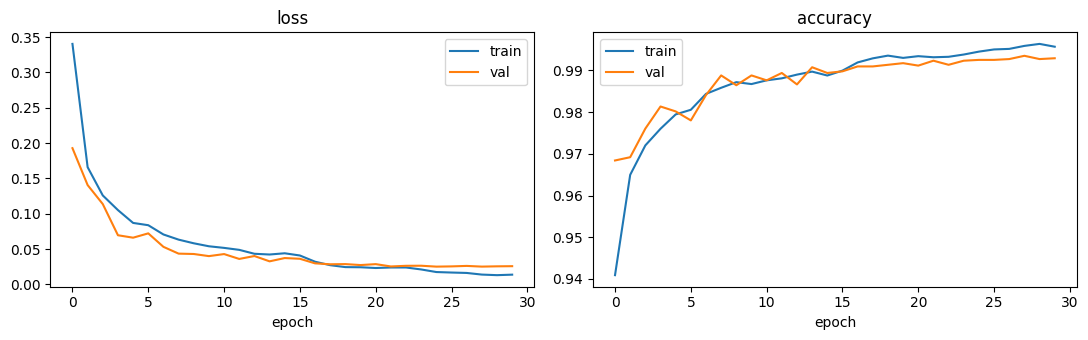

In [21]:
RNN_EPOCHS = 30
rnn_hist = rnn.fit(
    X_tr, y_tr_e, validation_data=(X_val, y_val_e), epochs=RNN_EPOCHS, batch_size=256,
    class_weight=ecg_class_weight, verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
               keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)],
)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, k in zip(ax, ["loss", "accuracy"]):
    a.plot(rnn_hist.history[k], label="train"); a.plot(rnn_hist.history["val_" + k], label="val")
    a.set_title(k); a.set_xlabel("epoch"); a.legend()
plt.tight_layout()
plt.show()

## B6. Evaluation on unseen patients (DS2)

Overall accuracy 0.866  (an 'always N' model would get 0.890!)
Macro-F1        0.502  ('always N' → 0.236)


,beats,sensitivity,PPV,F1
N,44218.0,0.891,0.963,0.926
S,1836.0,0.423,0.400,0.411
V,3219.0,0.872,0.509,0.643
F,388.0,0.057,0.017,0.026


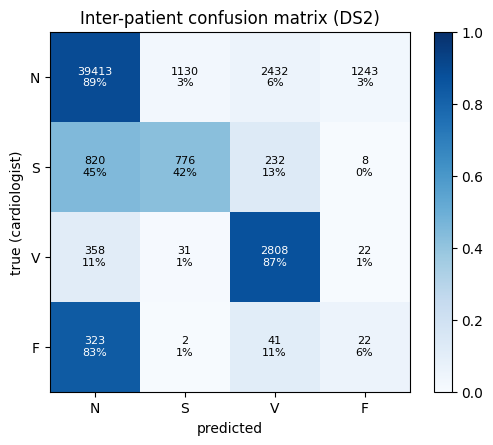

In [22]:
p_te = rnn.predict(X_te, batch_size=1024, verbose=0)
pred_te = p_te.argmax(1)

def aami_table(y, pred):
    cm = confusion_matrix(y, pred, labels=range(4))
    rows = {}
    for c in range(4):
        tp = cm[c, c]; fn = cm[c].sum() - tp; fp = cm[:, c].sum() - tp
        rows[CLASSES[c]] = {"beats": int(cm[c].sum()), "sensitivity": tp / max(tp + fn, 1),
                            "PPV": tp / max(tp + fp, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1)}
    return pd.DataFrame(rows).T, cm

table, cm = aami_table(y_te_e, pred_te)
naive_f1 = f1_score(y_te_e, np.zeros_like(y_te_e), average="macro", labels=range(4), zero_division=0)
print(f"Overall accuracy {np.mean(pred_te == y_te_e):.3f}  (an 'always N' model would get {np.mean(y_te_e == 0):.3f}!)")
print(f"Macro-F1        {f1_score(y_te_e, pred_te, average='macro', labels=range(4)):.3f}  ('always N' → {naive_f1:.3f})")
display(table.round(3))

plt.figure(figsize=(5.5, 4.5))
cm_norm = cm / cm.sum(1, keepdims=True)
plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=8,
                 color="white" if cm_norm[i, j] > 0.5 else "black")
plt.xticks(range(4), CLASSES); plt.yticks(range(4), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true (cardiologist)"); plt.title("Inter-patient confusion matrix (DS2)")
plt.colorbar(); plt.tight_layout(); plt.show()

**Reading the results.** V beats (wide, bizarre QRS) are usually detected well. **S beats are the hard class**
in the inter-patient setting: their shape is nearly normal and only their timing gives them away, and only a handful
of training patients have many of them. Published inter-patient methods typically trade S sensitivity against S PPV —
this is an open research problem, not a bug.

### Per-patient view & an annotated ECG strip

,beats,abnormal beats,accuracy,V sens,S sens
record,,,,,
100,2271.0,34.0,1.000,1.000,1.000
103,2082.0,2.0,1.000,0.000,0.500
105,2565.0,41.0,0.949,0.902,0.000
111,2122.0,1.0,0.960,1.000,0.000
113,1793.0,6.0,0.996,0.000,1.000
117,1533.0,1.0,0.736,0.000,1.000
121,1861.0,2.0,0.999,1.000,0.000
123,1516.0,3.0,0.985,1.000,0.000
200,2599.0,857.0,0.954,0.930,0.100


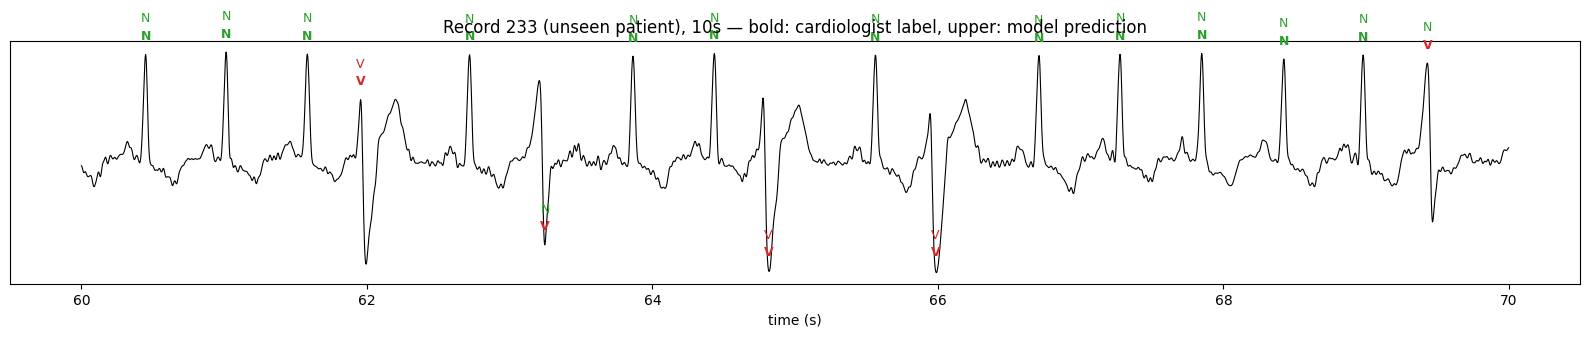

In [23]:
per_patient = (pd.DataFrame({"record": REC2, "true": y_te_e, "pred": pred_te})
               .groupby("record").apply(lambda d: pd.Series({
                   "beats": len(d), "abnormal beats": int((d.true > 0).sum()),
                   "accuracy": (d.true == d.pred).mean(),
                   "V sens": ((d.true == 2) & (d.pred == 2)).sum() / max((d.true == 2).sum(), 1),
                   "S sens": ((d.true == 1) & (d.pred == 1)).sum() / max((d.true == 1).sum(), 1)}), include_groups=False))
display(per_patient.round(3))

REC, START_S, DUR_S = "233", 60, 10
sig = clean(records[REC]["signal"])
a, b = START_S * FS, (START_S + DUR_S) * FS
m = (REC2 == REC) & (P2 >= a) & (P2 < b)
plt.figure(figsize=(16, 3.5))
plt.plot(np.arange(a, b) / FS, sig[a:b], lw=0.8, color="k")
colors = {"N": "tab:green", "S": "tab:orange", "V": "tab:red", "F": "tab:purple"}
for pos, t, p in zip(P2[m], y_te_e[m], pred_te[m]):
    plt.text(pos / FS, sig[pos] + 0.6, CLASSES[t], color=colors[CLASSES[t]], ha="center", fontsize=9, weight="bold")
    plt.text(pos / FS, sig[pos] + 1.3, CLASSES[p], color=colors[CLASSES[p]], ha="center", fontsize=9)
plt.title(f"Record {REC} (unseen patient), {DUR_S}s — bold: cardiologist label, upper: model prediction")
plt.xlabel("time (s)"); plt.yticks([])
plt.tight_layout(); plt.show()

In [24]:
rnn.save("models/ecg_cnn_bilstm.keras")
np.savez("models/ecg_rr_scaler.npz", mean=rr_mean, std=rr_std)
print("Saved models/ecg_cnn_bilstm.keras (+ RR scaler)")

Saved models/ecg_cnn_bilstm.keras (+ RR scaler)


---
## Summary
| | Pneumonia CNN | Arrhythmia RNN |
|---|---|---|
| Data | 5,856 pediatric chest X-rays | 44 patients, ~100k labelled beats |
| Model | EfficientNet-B0 + fine-tuning | Conv1D → 2× BiLSTM + RR-interval features |
| Evaluation | held-out test set, ROC-AUC, sensitivity-targeted threshold, Grad-CAM | inter-patient (unseen patients), AAMI per-class Se / PPV, macro-F1 |

**Limitations / next steps**
* X-rays come from a single hospital and only children 1–5 years → external validation on another site is needed before any claim of generalisation.
* The Kaggle X-ray release has no patient IDs, so the *validation* split may share patients with training (the official test set is separate).
* ECG: S-beat detection on new patients remains weak — patient-adaptive fine-tuning, more leads, or larger databases (INCART, PTB-XL) are the usual next steps.

### Download the trained models (Colab)
Colab files are deleted when the session ends.

In [25]:
import shutil
shutil.make_archive("clinical_models", "zip", "models")
try:
    from google.colab import files
    files.download("clinical_models.zip")
except ImportError:
    print("Not on Colab — models saved to clinical_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>